imports

In [28]:
import requests 
import pandas as pd
from dotenv import load_dotenv
import os
import matplotlib.pyplot as plt

#RUN "python -m pip install requests" AND "python -m pip install dotenv"
#And "python -m pip install matplotlib" if that isn't working

dowloading the data


In [16]:
#Get's the data from .env file where you have CLIENT_ID=YOUR_CODE do not use "" nor space
#Also very important to make sure .env is saved on your computer to make sure it works. so if it fails,
# ctrl + s on the .env file and try again
load_dotenv() 
client_id = os.getenv("CLIENT_ID")

# Define endpoint and parameters
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
    'sources': 'SN17850', # source ID for Ås 
    'elements': 'mean(air_temperature P1D),sum(precipitation_amount P1D),mean(wind_speed P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}

# Issue an HTTP GET request
r = requests.get(endpoint, parameters, auth=(client_id,''))
# Extract JSON data
json = r.json()


# IMPORTANT!!! the following can be changed or removed as you see fit. as it's not important for the task

# Check if the request worked, print out any errors
if r.status_code == 200:
    data = json['data']
    print('Data retrieved from frost.met.no!')
else:
    print('Error! Returned status code %s' % r.status_code)
    print('Message: %s' % json['error']['message'])
    print('Reason: %s' % json['error']['reason'])  

Data retrieved from frost.met.no!


Printing the data


In [17]:
# This will return a Dataframe with all of the observations in a table format
df = pd.DataFrame()
rows = []


# Organising the data
for i in range(len(data)):
    row = pd.DataFrame(data[i]['observations'])
    row['referenceTime'] = data[i]['referenceTime']
    row['sourceId'] = data[i]['sourceId']
    rows.append(row)


df= pd.concat(rows, ignore_index=True)

df = df.reset_index()
print(df.head())

   index                      elementId  value  unit  \
0      0      mean(air_temperature P1D)   -5.2  degC   
1      1      mean(air_temperature P1D)   -2.8  degC   
2      2  sum(precipitation_amount P1D)    5.4    mm   
3      3  sum(precipitation_amount P1D)    6.6    mm   
4      4      mean(air_temperature P1D)  -11.5  degC   

                                               level timeOffset  \
0  {'levelType': 'height_above_ground', 'unit': '...       PT0H   
1  {'levelType': 'height_above_ground', 'unit': '...       PT6H   
2                                                NaN      PT18H   
3                                                NaN       PT6H   
4  {'levelType': 'height_above_ground', 'unit': '...       PT0H   

  timeResolution  timeSeriesId performanceCategory exposureCategory  \
0            P1D             0                   C                1   
1            P1D             0                   C                1   
2            P1D             0                 

In [18]:
# These additional columns will be kept
columns = ['sourceId','referenceTime','elementId','value','unit','timeOffset']
df2 = df[columns].copy()
# Convert the time value to something Python understands
df2['referenceTime'] = pd.to_datetime(df2['referenceTime'])

print(df2.head())

    sourceId             referenceTime                      elementId  value  \
0  SN17850:0 2025-01-01 00:00:00+00:00      mean(air_temperature P1D)   -5.2   
1  SN17850:0 2025-01-01 00:00:00+00:00      mean(air_temperature P1D)   -2.8   
2  SN17850:0 2025-01-01 00:00:00+00:00  sum(precipitation_amount P1D)    5.4   
3  SN17850:0 2025-01-01 00:00:00+00:00  sum(precipitation_amount P1D)    6.6   
4  SN17850:0 2025-01-02 00:00:00+00:00      mean(air_temperature P1D)  -11.5   

   unit timeOffset  
0  degC       PT0H  
1  degC       PT6H  
2    mm      PT18H  
3    mm       PT6H  
4  degC       PT0H  


Task 1: Temperature
# the above is kept mostly the same from the example file and can be copied and repuprosed for the folloeing tasks if necesary. 

In [30]:
# Getting personal ID from the .env file
load_dotenv() 
client_id = os.getenv("CLIENT_ID")

# Downloading the data for temperature
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
'sources': 'SN17850', # sourceID for Ås
'elements': 'mean(air_temperature P1D)',
'referencetime': '2025-01-01/2025-12-31',
}

# Issue an HTTP GET request
r = requests.get(endpoint, parameters, auth=(client_id,''))
# Extract JSON data
json = r.json()
data = json['data']

temp = pd.DataFrame()
rows = []


# Organising the data
for i in range(len(data)):
    row = pd.DataFrame(data[i]['observations'])
    row['referenceTime'] = data[i]['referenceTime']
    row['sourceId'] = data[i]['sourceId']
    rows.append(row)


temp = pd.concat(rows, ignore_index=True)

temp = temp.reset_index()

# To get the actual average temperature 
average_temp = temp["value"].mean()
print("average temperature during 2025 is ", average_temp)

average temperature during 2025 is  7.903571428571428


2. Precipitation

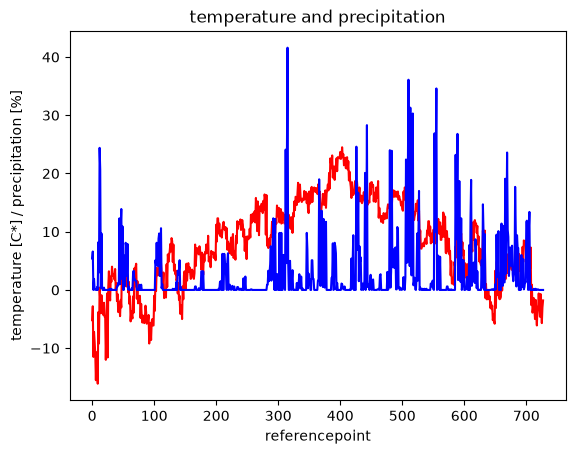

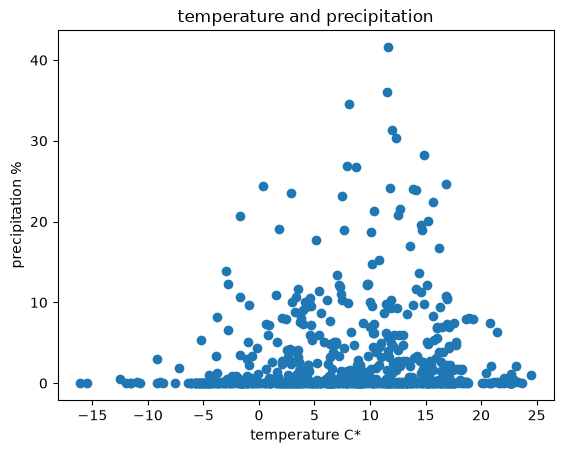

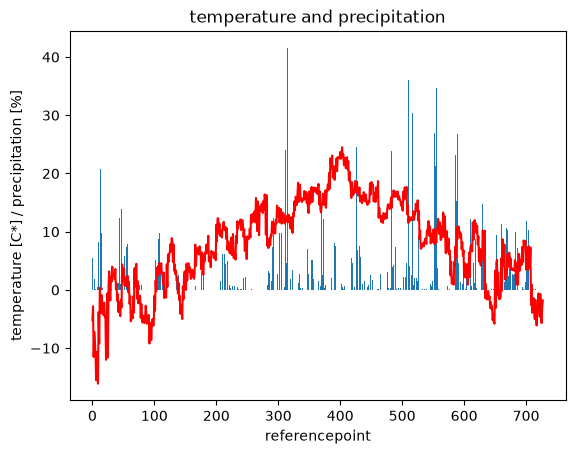

In [ ]:
load_dotenv() 
client_id = os.getenv("CLIENT_ID")


# Downloading the data, for precipitation
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
'sources': 'SN17850', # sourceID for Ås
'elements': 'sum(precipitation_amount P1D)',
'referencetime': '2025-01-01/2025-12-31',
}

# Issue an HTTP GET request
r = requests.get(endpoint, parameters, auth=(client_id,''))
# Extract JSON data
json = r.json()
data = json['data']

precipitation = pd.DataFrame()
rows = []


# Organising the data
for i in range(len(data)):
    row = pd.DataFrame(data[i]['observations'])
    row['referenceTime'] = data[i]['referenceTime']
    row['sourceId'] = data[i]['sourceId']
    rows.append(row)


precipitation = pd.concat(rows, ignore_index=True)

precipitation = precipitation.reset_index()

precipitation_value = precipitation["value"]
temp_value = temp["value"]

# Graph with both as lines
plt.title("temperature and precipitation")
plt.plot(temp_value, label="temperature", color = "red")
plt.plot(precipitation_value, label="precipitation", color = "blue")
plt.xlabel("referencepoint")
plt.ylabel("temperature [C*] / precipitation [%]")
plt.show()

# Scatter plot to show relations between temperature and precipitation
plt.title("temperature and precipitation")
plt.scatter(temp_value, precipitation_value)
plt.xlabel("temperature C*")
plt.ylabel("precipitation %")
plt.show()

# Graph with precipitation as bar, 
plt.title("temperature and precipitation")
plt.plot(temp_value, label="temperature", color = "red")
plt.bar(range(len(precipitation_value)), precipitation_value)
plt.xlabel("referencepoint")
plt.ylabel("temperature [C*] / precipitation [%]")
plt.show()

# A pie chart simply does not make sense in this type of graph, 
# so the question comes down to what we are tyring to find when trying to score the best graph
# On that front the scatter graph helps show a corelation between temperature and precipitation
# Though for a simple overwiev over how both evolve over time I think a simple line graph works good enough 

